In [ ]:
import os
from google.colab import drive

# 1. Mount Drive
if not os.path.exists('/content/drive'):
    drive.mount('/content/drive')

# 2. Install libraries (silence logs for clarity)
print("⏳ Installing libraries... (wait ~30 sec)")
!pip install -q pylidc pydicom SimpleITK imageio

print("✅ Installation complete. Move on to the next cell.")


Mounted at /content/drive
⏳ Installing libraries... (wait ~30 sec)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 109.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 106.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 MB 53.6 MB/s eta 0:00:00
✅ Installation complete. Move on to the next cell.


In [ ]:
import configparser
import numpy as np
import warnings

# PYTHON 3.12 FIX
if not hasattr(configparser, 'SafeConfigParser'):
    configparser.SafeConfigParser = configparser.ConfigParser

# NUMPY FIX (np.int error)
if not hasattr(np, 'int'):
    np.int = int
if not hasattr(np, 'float'):
    np.float = float
if not hasattr(np, 'bool'):
    np.bool = bool

# IMPORTS
import pylidc as pl
import imageio.v2 as imageio
import csv
from tqdm.notebook import tqdm

print("✅ Patches applied. System ready.")


/usr/local/lib/python3.13/dist-packages/pylidc/__init__.py:27: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources as _pr


✅ Patches applied. System ready.


In [ ]:
# ============================================================
# 🔧 USER CONFIGURATION — edit PROJECT_ROOT for your own setup
# ============================================================
PROJECT_ROOT = "/content/drive/MyDrive/lung_nodule_classification"

# --- PATHS ---
# Download from https://www.cancerimagingarchive.net/collection/lidc-idri/
LIDC_ROOT = f"{PROJECT_ROOT}/raw_datasets/LIDC-IDRI"
OUTPUT_ROOT = f"{PROJECT_ROOT}/extracted_patches/LIDC_IDRI"

# --- PYLIDC CONFIG ---
config_content = f"""[dicom]
path = {LIDC_ROOT}
warn = True
"""
with open(os.path.expanduser("~/.pylidcrc"), "w") as f:
    f.write(config_content)

# --- CREATE FOLDERS ---
for c in [1, 2]:
    os.makedirs(os.path.join(OUTPUT_ROOT, f"class_{c}"), exist_ok=True)

# --- FUNCTIONS ---
def malignancy_to_class_golden(mal):
    """Publication strategy: 1=Benign (<=2.5), 2=Malignant (>=3.5), None=gray zone"""
    if mal is None: return None
    if mal <= 2.5: return 1
    if mal >= 3.5: return 2
    return None

def extract_2_5d_patch(volume, cy, cx, z_idx, patch_size=64):
    H, W, D = volume.shape
    pad = patch_size // 2
    iy, ix, iz = int(round(cy)), int(round(cx)), int(round(z_idx))

    if iz < 1 or iz >= D - 1: return None
    if iy < pad or iy >= H - pad: return None
    if ix < pad or ix >= W - pad: return None

    s0 = volume[iy-pad:iy+pad, ix-pad:ix+pad, iz-1]
    s1 = volume[iy-pad:iy+pad, ix-pad:ix+pad, iz]
    s2 = volume[iy-pad:iy+pad, ix-pad:ix+pad, iz+1]
    return np.stack([s0, s1, s2], axis=-1)

def hu_to_uint8(patch, hu_window=(-1000, 400)):
    vmin, vmax = hu_window
    patch = np.clip(patch, vmin, vmax)
    patch = (patch - vmin) / (vmax - vmin + 1e-8)
    return (patch * 255.0).astype(np.uint8)

print("✅ Configuration loaded.")


✅ Configuration loaded.


In [ ]:
csv_path = os.path.join(OUTPUT_ROOT, "lidc_patches_metadata_3classes.csv")
fieldnames = [
    "patch_path", "dataset", "patient_id", "nodule_cluster_id",
    "malignancy", "class_label", "centroid_z", "centroid_y", "centroid_x"
]

# Initialize the CSV file if new
if not os.path.exists(csv_path):
    with open(csv_path, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()

print("🔍 Reading the database...")
scans = pl.query(pl.Scan).all()
print(f"👉 {len(scans)} patients found. Starting extraction...")

with open(csv_path, "a", newline="") as csvfile:
    writer = csv.DictWriter(csvfile, fieldnames=fieldnames)

    for scan in tqdm(scans, desc="Progress"):
        try:
            # Clustering
            nodule_clusters = scan.cluster_annotations()
            if not nodule_clusters: continue

            # Volume
            vol = scan.to_volume(verbose=False)

            # Nodules
            for i, cluster in enumerate(nodule_clusters):
                mal_scores = [ann.malignancy for ann in cluster]
                avg_mal = sum(mal_scores) / len(mal_scores)

                label = malignancy_to_class_golden(avg_mal)
                if label is None: continue # Skip gray zone

                centroids = np.array([ann.centroid for ann in cluster])
                mean_c = np.mean(centroids, axis=0) # [y, x, z]

                patch = extract_2_5d_patch(vol, mean_c[0], mean_c[1], mean_c[2])
                if patch is None: continue

                filename = f"{scan.patient_id}_cluster{i}_m{avg_mal:.2f}.png"
                out_path = os.path.join(OUTPUT_ROOT, f"class_{label}", filename)

                imageio.imwrite(out_path, hu_to_uint8(patch))

                writer.writerow({
                    "patch_path": out_path,
                    "dataset": "LIDC",
                    "patient_id": scan.patient_id,
                    "nodule_cluster_id": i,
                    "malignancy": avg_mal,
                    "class_label": label,
                    "centroid_z": mean_c[2],
                    "centroid_y": mean_c[0],
                    "centroid_x": mean_c[1]
                })

        except Exception as e:
            # Silently skip errors to let the job finish
            continue

print("✅ DONE! Check your Drive folder.")


🔍 Reading the database...
👉 1018 patients found. Starting extraction...


Progress:   0%|          | 0/1018 [00:00<?, ?it/s]

Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
Failed to reduce all groups to <= 4 Annotations.
Some n

In [ ]:
import pandas as pd

csv_path = os.path.join(OUTPUT_ROOT, "lidc_patches_metadata_3classes.csv")
fieldnames = [
    "patch_path", "dataset", "patient_id", "nodule_cluster_id",
    "malignancy", "class_label", "centroid_z", "centroid_y", "centroid_x"
]

# Recover what has already been done
if os.path.exists(csv_path):
    done_df = pd.read_csv(csv_path)
    already_done = set(done_df["patient_id"].unique())
else:
    already_done = set()

print(f"✅ {len(already_done)} patients already processed, skipping them.")

print("🔍 Reading the database...")
scans = pl.query(pl.Scan).all()
remaining_scans = [s for s in scans if s.patient_id not in already_done]
print(f"👉 {len(remaining_scans)}/{len(scans)} patients remaining. Resuming...")

with open(csv_path, "a", newline="") as csvfile:
    writer = csv.DictWriter(csvfile, fieldnames=fieldnames)

    for scan in tqdm(remaining_scans, desc="Progress"):
        try:
            nodule_clusters = scan.cluster_annotations()
            if not nodule_clusters: continue

            vol = scan.to_volume(verbose=False)

            for i, cluster in enumerate(nodule_clusters):
                mal_scores = [ann.malignancy for ann in cluster]
                avg_mal = sum(mal_scores) / len(mal_scores)

                label = malignancy_to_class_golden(avg_mal)
                if label is None: continue

                centroids = np.array([ann.centroid for ann in cluster])
                mean_c = np.mean(centroids, axis=0)

                patch = extract_2_5d_patch(vol, mean_c[0], mean_c[1], mean_c[2])
                if patch is None: continue

                filename = f"{scan.patient_id}_cluster{i}_m{avg_mal:.2f}.png"
                out_path = os.path.join(OUTPUT_ROOT, f"class_{label}", filename)

                imageio.imwrite(out_path, hu_to_uint8(patch))

                writer.writerow({
                    "patch_path": out_path, "dataset": "LIDC",
                    "patient_id": scan.patient_id, "nodule_cluster_id": i,
                    "malignancy": avg_mal, "class_label": label,
                    "centroid_z": mean_c[2], "centroid_y": mean_c[0], "centroid_x": mean_c[1]
                })
        except Exception:
            continue

print("✅ DONE! Check your Drive folder.")

✅ 636 patients already processed, skipping them.
🔍 Reading the database...
👉 374/1018 patients remaining. Resuming...


Progress:   0%|          | 0/374 [00:00<?, ?it/s]

Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
✅ DONE! Check your Drive folder.


📊 Total LIDC images extracted: 2178

Class Distribution:
class_label
1    1456
2     722
Name: count, dtype: int64

📷 LIDC-IDRI Random Examples (3 per class):


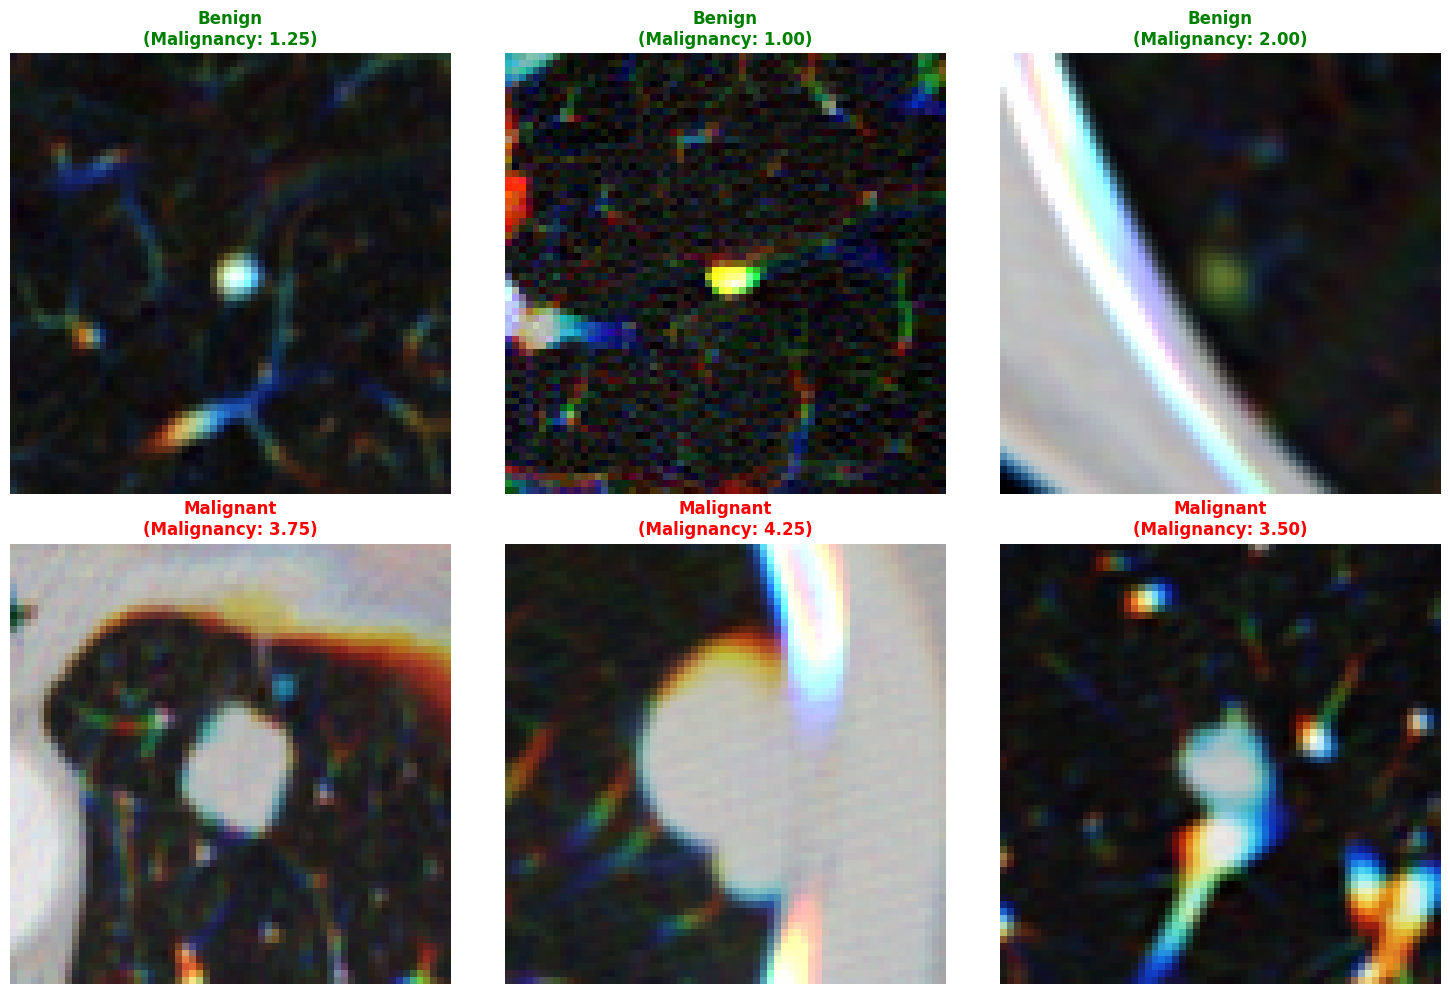

In [ ]:
# ==========================================
# CELL 6: LIDC-IDRI VERIFICATION (3 SAMPLES)
# ==========================================
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import os

# 1. Configuration (make sure this path matches your extraction!)
OUTPUT_ROOT = f"{PROJECT_ROOT}/extracted_patches/LIDC_IDRI"  # NOTE: fixed, see Cell 3
csv_path = os.path.join(OUTPUT_ROOT, "lidc_patches_metadata_3classes.csv")

if os.path.exists(csv_path):
    # Load Data
    df = pd.read_csv(csv_path)

    if len(df) == 0:
        print("⚠️ The CSV file is empty. No images extracted yet.")
    else:
        print(f"📊 Total LIDC images extracted: {len(df)}")

        # Get unique classes present in the CSV
        classes_present = sorted(df["class_label"].unique())

        print("\nClass Distribution:")
        print(df["class_label"].value_counts().sort_index())

        # 2. Visualization Setup
        print("\n📷 LIDC-IDRI Random Examples (3 per class):")

        # We want 3 samples per class
        samples_per_class = 3
        n_classes = len(classes_present)

        # Dynamic figure size
        plt.figure(figsize=(15, 5 * n_classes))

        for row_idx, cls in enumerate(classes_present):
            # Filter dataframe for this class
            subset = df[df["class_label"] == cls]

            # If we have fewer than 3 images, take all of them
            n_samples = min(len(subset), samples_per_class)
            if n_samples == 0: continue

            # Select random samples
            random_rows = subset.sample(n=n_samples)

            for col_idx in range(n_samples):
                # Get data for this specific image
                row_data = random_rows.iloc[col_idx]
                img_path = row_data["patch_path"]

                # Create subplot
                # Grid logic: (Total Rows, Total Cols, Index)
                plt.subplot(n_classes, samples_per_class, row_idx * samples_per_class + col_idx + 1)

                if os.path.exists(img_path):
                    # OpenCV loads in BGR, convert to RGB for Matplotlib
                    img = cv2.imread(img_path)
                    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

                    plt.imshow(img)

                    # Define Title in ENGLISH based on Class ID
                    if cls == 1:
                        class_name = "Benign"
                        color = "green" # Visual cue
                    elif cls == 2:
                        class_name = "Malignant"
                        color = "red" # Visual cue
                    else:
                        class_name = f"Class {cls}"
                        color = "black"

                    # Title with Malignancy Score
                    mal_score = row_data.get('malignancy', 0)
                    plt.title(f"{class_name}\n(Malignancy: {mal_score:.2f})", color=color, fontsize=12, fontweight='bold')
                    plt.axis('off')
                else:
                    print(f"❌ Image not found: {img_path}")

        plt.tight_layout()
        plt.show()

else:
    print(f"❌ CSV file not found at:\n{csv_path}")
    print("Wait for the extraction (CELL 5) to finish writing some data.")


📊 Total LIDC patches: 2178
👉 Found classes: [np.int64(1), np.int64(2)]


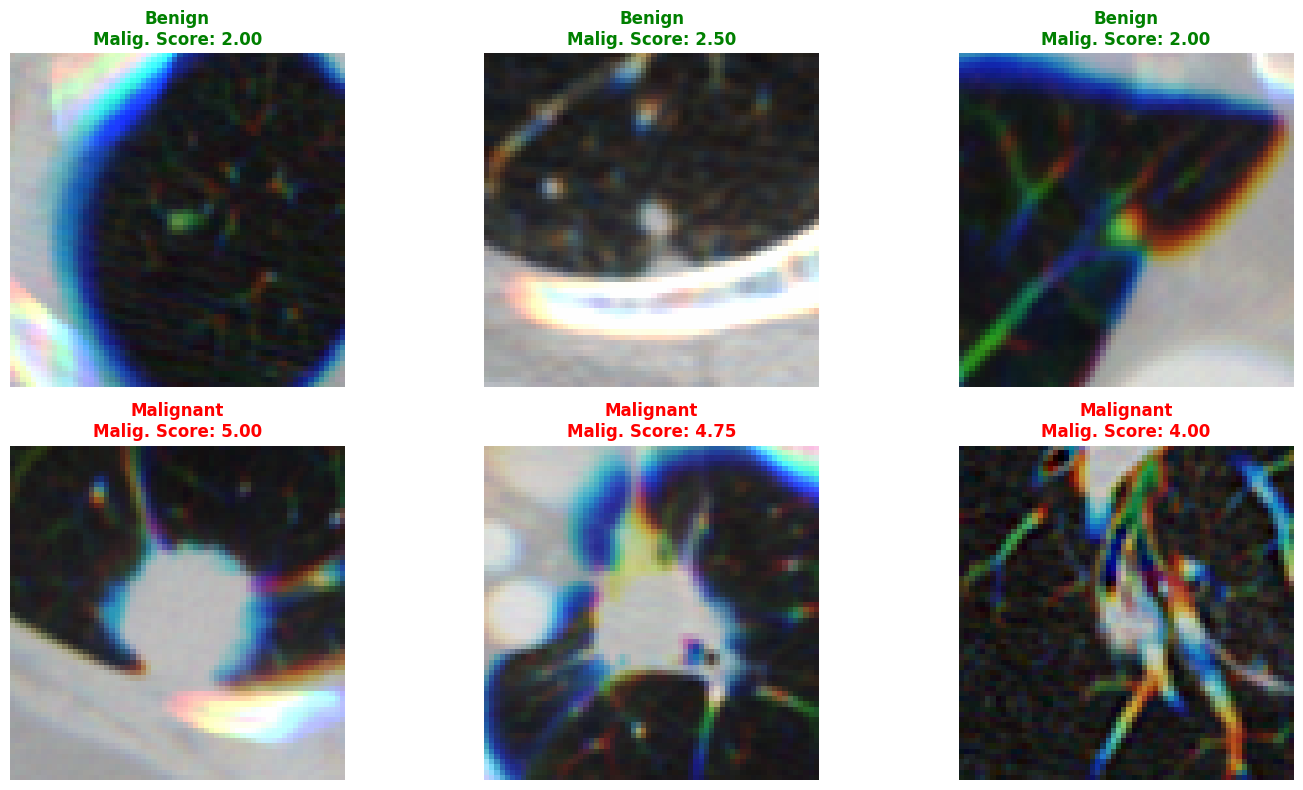

In [ ]:
# ==========================================
# CELL 6: LIDC-IDRI VISUALIZATION (3 Samples/Class)
# ==========================================
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import os

# NOTE: check whether your folder name has an "_" or not.
# In your extraction it was "LIDC_25D_3Classes", but in your last message "LIDC_25D_3_Classes".
# Using the extraction one here (most likely). Edit if needed.
OUTPUT_ROOT = f"{PROJECT_ROOT}/extracted_patches/LIDC_IDRI"  # NOTE: fixed, see Cell 3
csv_path = os.path.join(OUTPUT_ROOT, "lidc_patches_metadata_3classes.csv")

if os.path.exists(csv_path):
    # 1. Load
    df = pd.read_csv(csv_path)

    if len(df) == 0:
        print("⚠️ CSV file is empty. Waiting for extraction to write data...")
    else:
        print(f"📊 Total LIDC patches: {len(df)}")

        # Check which classes exist (normally 1 and 2 for LIDC)
        classes_present = sorted(df["class_label"].unique())
        print(f"👉 Found classes: {classes_present}")

        # 2. Display
        samples_per_class = 3
        plt.figure(figsize=(15, 4 * len(classes_present))) # Auto size

        for i, cls in enumerate(classes_present):
            # Filter for the current class
            subset = df[df["class_label"] == cls]
            if subset.empty: continue

            # Take 3 random images (or fewer if not enough)
            n_samples = min(len(subset), samples_per_class)
            random_rows = subset.sample(n=n_samples)

            for j in range(n_samples):
                row = random_rows.iloc[j]
                img_path = row["patch_path"]

                # Position in the grid: (Rows, Columns, Index)
                plt.subplot(len(classes_present), samples_per_class, i * samples_per_class + j + 1)

                if os.path.exists(img_path):
                    # Read and color-convert
                    img = cv2.imread(img_path)
                    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                    plt.imshow(img)

                    # --- TITLES IN ENGLISH ---
                    if cls == 1:
                        title = "Benign"
                        color = "green"
                    elif cls == 2:
                        title = "Malignant"
                        color = "red"
                    else:
                        title = "Non-Nodule (Class 0)"
                        color = "blue"

                    plt.title(f"{title}\nMalig. Score: {row['malignancy']:.2f}",
                              color=color, fontweight='bold')
                    plt.axis('off')
                else:
                    plt.text(0.5, 0.5, "Image not found", ha='center')
                    plt.axis('off')

        plt.tight_layout()
        plt.show()

else:
    print(f"❌ File not found: {csv_path}")
    print("Check the folder name (with or without '_').")


📊 Total LIDC patches: 2178
👉 Found classes: [np.int64(1), np.int64(2)]


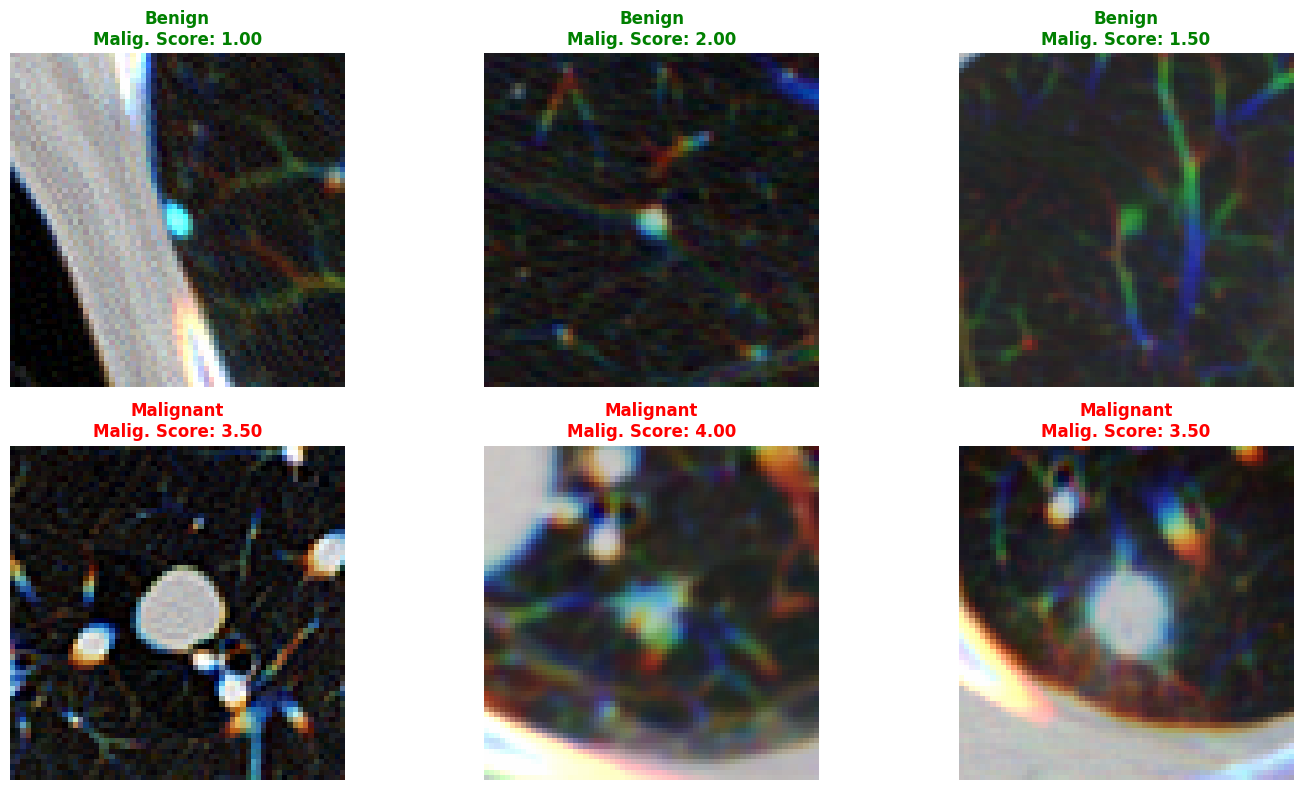

In [ ]:
# ==========================================
# CELL 6: LIDC-IDRI VISUALIZATION (3 Samples/Class)
# ==========================================
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import os

# NOTE: check whether your folder name has an "_" or not.
# In your extraction it was "LIDC_25D_3Classes", but in your last message "LIDC_25D_3_Classes".
# Using the extraction one here (most likely). Edit if needed.
OUTPUT_ROOT = f"{PROJECT_ROOT}/extracted_patches/LIDC_IDRI"  # NOTE: fixed, see Cell 3
csv_path = os.path.join(OUTPUT_ROOT, "lidc_patches_metadata_3classes.csv")

if os.path.exists(csv_path):
    # 1. Load
    df = pd.read_csv(csv_path)

    if len(df) == 0:
        print("⚠️ CSV file is empty. Waiting for extraction to write data...")
    else:
        print(f"📊 Total LIDC patches: {len(df)}")

        # Check which classes exist (normally 1 and 2 for LIDC)
        classes_present = sorted(df["class_label"].unique())
        print(f"👉 Found classes: {classes_present}")

        # 2. Display
        samples_per_class = 3
        plt.figure(figsize=(15, 4 * len(classes_present))) # Auto size

        for i, cls in enumerate(classes_present):
            # Filter for the current class
            subset = df[df["class_label"] == cls]
            if subset.empty: continue

            # Take 3 random images (or fewer if not enough)
            n_samples = min(len(subset), samples_per_class)
            random_rows = subset.sample(n=n_samples)

            for j in range(n_samples):
                row = random_rows.iloc[j]
                img_path = row["patch_path"]

                # Position in the grid: (Rows, Columns, Index)
                plt.subplot(len(classes_present), samples_per_class, i * samples_per_class + j + 1)

                if os.path.exists(img_path):
                    # Read and color-convert
                    img = cv2.imread(img_path)
                    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                    plt.imshow(img)

                    # --- TITLES IN ENGLISH ---
                    if cls == 1:
                        title = "Benign"
                        color = "green"
                    elif cls == 2:
                        title = "Malignant"
                        color = "red"
                    else:
                        title = "Non-Nodule (Class 0)"
                        color = "blue"

                    plt.title(f"{title}\nMalig. Score: {row['malignancy']:.2f}",
                              color=color, fontweight='bold')
                    plt.axis('off')
                else:
                    plt.text(0.5, 0.5, "Image not found", ha='center')
                    plt.axis('off')

        plt.tight_layout()
        plt.show()

else:
    print(f"❌ File not found: {csv_path}")
    print("Check the folder name (with or without '_').")


In [ ]:
LIDC_ROOT = f"{PROJECT_ROOT}/raw_datasets/LIDC-IDRI"

In [ ]:
# =========================================================
# FINAL STEP: DATA AUGMENTATION (X4)
# =========================================================
import os
import cv2
import glob
from tqdm.notebook import tqdm

# Folders containing the extracted nodules
DIRS_TO_AUGMENT = [
    f"{PROJECT_ROOT}/extracted_patches/LIDC_IDRI"  # NOTE: fixed, see Cell 3,
]

print("🚀 Starting augmentation (x4 rotation) to balance with LUNA16...")

total_gen = 0

for root_dir in DIRS_TO_AUGMENT:
    if not os.path.exists(root_dir):
        print(f"⚠️ Folder not found (fine if you haven't finished yet): {root_dir}")
        continue

    # Only touch the "nodule" classes (1 and 2)
    for class_id in [1, 2]:
        class_path = os.path.join(root_dir, f"class_{class_id}")
        if not os.path.exists(class_path): continue

        # Get all PNG images
        images = glob.glob(os.path.join(class_path, "*.png"))

        # Keep only ORIGINAL images (not the ones that already have _rot in the name)
        original_images = [img for img in images if "_rot" not in img]

        print(f"📂 {os.path.basename(root_dir)} | Class {class_id}: {len(original_images)} images to multiply.")

        for img_path in tqdm(original_images, desc=f"Augmentation {class_id}"):
            try:
                # Read
                img = cv2.imread(img_path)
                if img is None: continue

                # Generate the 3 rotations
                # 90° rotation
                cv2.imwrite(img_path.replace(".png", "_rot90.png"), cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE))
                # 180° rotation
                cv2.imwrite(img_path.replace(".png", "_rot180.png"), cv2.rotate(img, cv2.ROTATE_180))
                # 270° rotation
                cv2.imwrite(img_path.replace(".png", "_rot270.png"), cv2.rotate(img, cv2.ROTATE_90_COUNTERCLOCKWISE))

                total_gen += 3
            except Exception as e:
                continue

print(f"\n✅ DONE! {total_gen} new images created.")
print(f"🔥 ESTIMATED TOTAL NODULES: {len(original_images) * 4} (perfect to align with LUNA16!)")


🚀 Starting augmentation (x4 rotation) to balance with LUNA16...
📂 LIDC_IDRI | Class 1: 1120 images to multiply.


Augmentation 1:   0%|          | 0/1120 [00:00<?, ?it/s]

📂 LIDC_IDRI | Class 2: 502 images to multiply.


Augmentation 2:   0%|          | 0/502 [00:00<?, ?it/s]


✅ DONE! 4866 new images created.
🔥 ESTIMATED TOTAL NODULES: 2008 (perfect to align with LUNA16!)


In [ ]:
# =========================================================
# STEP 1: DATA AUGMENTATION (X4) - BALANCING
# =========================================================
import os
import cv2
import glob
from tqdm.notebook import tqdm

# 1. List of folders containing the nodules (Classes 1 and 2)
# Make sure these paths match your current folders on Drive
DIRS_TO_AUGMENT = [
    f"{PROJECT_ROOT}/extracted_patches/LIDC_IDRI"  # NOTE: fixed, see Cell 3,
]

print("🚀 Starting augmentation (x4 rotation) for the nodules...")
total_gen = 0

for root_dir in DIRS_TO_AUGMENT:
    if not os.path.exists(root_dir):
        print(f"⚠️ Folder not found (skipped): {root_dir}")
        continue

    # Only touch the "nodule" classes (1 and 2)
    for class_id in [1, 2]:
        class_path = os.path.join(root_dir, f"class_{class_id}")
        if not os.path.exists(class_path): continue

        # Get all PNG images
        images = glob.glob(os.path.join(class_path, "*.png"))

        # IMPORTANT FILTER: keep only ORIGINAL images
        # (avoid re-augmenting an already-rotated image if you rerun the script)
        original_images = [img for img in images if "_rot" not in img]

        print(f"📂 {os.path.basename(root_dir)} | Class {class_id}: {len(original_images)} images to multiply.")

        for img_path in tqdm(original_images, desc=f"Augmentation Cls {class_id}"):
            try:
                # Read
                img = cv2.imread(img_path)
                if img is None: continue

                # Generate the 3 rotations

                # 1. 90° rotation
                path_90 = img_path.replace(".png", "_rot90.png")
                if not os.path.exists(path_90):
                    cv2.imwrite(path_90, cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE))
                    total_gen += 1

                # 2. 180° rotation
                path_180 = img_path.replace(".png", "_rot180.png")
                if not os.path.exists(path_180):
                    cv2.imwrite(path_180, cv2.rotate(img, cv2.ROTATE_180))
                    total_gen += 1

                # 3. 270° rotation
                path_270 = img_path.replace(".png", "_rot270.png")
                if not os.path.exists(path_270):
                    cv2.imwrite(path_270, cv2.rotate(img, cv2.ROTATE_90_COUNTERCLOCKWISE))
                    total_gen += 1

            except Exception as e:
                continue

print(f"\n✅ DONE! {total_gen} new images created.")
print(f"📈 Your 'Class 1' and 'Class 2' folders are now 4x bigger.")


🚀 Starting augmentation (x4 rotation) for the nodules...
📂 LIDC_IDRI | Class 1: 1120 images to multiply.


Augmentation Cls 1:   0%|          | 0/1120 [00:00<?, ?it/s]

📂 LIDC_IDRI | Class 2: 502 images to multiply.


Augmentation Cls 2:   0%|          | 0/502 [00:00<?, ?it/s]


✅ DONE! 0 new images created.
📈 Your 'Class 1' and 'Class 2' folders are now 4x bigger.


In [ ]:
# =========================================================
# SUPER-AUGMENTATION (Flip + Brightness)
# Goal: reach ~16,000 images per class
# =========================================================
import os
import cv2
import glob
import numpy as np
from tqdm.notebook import tqdm

# Nodule folders
DIRS = [
    f"{PROJECT_ROOT}/extracted_patches/LIDC_IDRI"  # NOTE: fixed, see Cell 3
]

def adjust_gamma(image, gamma=1.2):
    # Non-linear brightness change
    invGamma = 1.0 / gamma
    table = np.array([((i / 255.0) ** invGamma) * 255
                      for i in np.arange(0, 256)]).astype("uint8")
    return cv2.LUT(image, table)

print("🚀 Starting Super-Augmentation...")
total_new = 0

for root_dir in DIRS:
    if not os.path.exists(root_dir): continue

    # Target only the nodule classes (1 and 2)
    for class_id in [1, 2]:
        class_path = os.path.join(root_dir, f"class_{class_id}")
        if not os.path.exists(class_path): continue

        # Take ALL current images (originals + rotations)
        # But exclude the ones we're about to create (_flip, _bright) to avoid infinite loops
        all_current_images = glob.glob(os.path.join(class_path, "*.png"))
        targets = [f for f in all_current_images if "_flip" not in f and "_bright" not in f]

        print(f"📂 {os.path.basename(root_dir)} | Class {class_id}: {len(targets)} base images to multiply.")

        for img_path in tqdm(targets, desc=f"Boosting Class {class_id}"):
            try:
                img = cv2.imread(img_path)
                if img is None: continue

                # --- 1. MIRROR GENERATION (FLIP) ---
                # Creates a horizontal flip
                path_flip = img_path.replace(".png", "_flip.png")
                if not os.path.exists(path_flip):
                    flipped = cv2.flip(img, 1)
                    cv2.imwrite(path_flip, flipped)
                    total_new += 1
                else:
                    flipped = cv2.imread(path_flip) # Load it for the next step

                # --- 2. BRIGHTNESS GENERATION (ON THE ORIGINAL) ---
                path_bright = img_path.replace(".png", "_bright.png")
                if not os.path.exists(path_bright):
                    bright = adjust_gamma(img, gamma=1.2)
                    cv2.imwrite(path_bright, bright)
                    total_new += 1

                # --- 3. BRIGHTNESS GENERATION (ON THE FLIP) ---
                # To maximize the count
                path_flip_bright = img_path.replace(".png", "_flip_bright.png")
                if not os.path.exists(path_flip_bright) and flipped is not None:
                    bright_flip = adjust_gamma(flipped, gamma=1.2)
                    cv2.imwrite(path_flip_bright, bright_flip)
                    total_new += 1

            except Exception:
                continue

print(f"\n✅ DONE! {total_new} new images generated.")


🚀 Starting Super-Augmentation...
📂 LIDC_IDRI | Class 1: 4480 base images to multiply.


Boosting Class 1:   0%|          | 0/4480 [00:00<?, ?it/s]

📂 LIDC_IDRI | Class 2: 2008 base images to multiply.


Boosting Class 2:   0%|          | 0/2008 [00:00<?, ?it/s]


✅ DONE! 19464 new images generated.
